In [ ]:
import pandas  as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
#pip install kagglehub

In [ ]:
#from google.colab import files
#files.upload()

In [ ]:
data=pd.read_csv("User_Eng.csv")

In [ ]:
data.head(6)

,index,Random,course_id,userid_DI,registered,viewed,explored,certified,final_cc_cname_DI,LoE_DI,...,grade,start_time_DI,last_event_DI,nevents,ndays_act,nplay_video,nchapters,nforum_posts,roles,incomplete_flag
0,0,86,HarvardX/CB22x/2013_Spring,MHxPC130442623,1,0,0,0,United States,NaN,...,0,12/19/2012,11/17/2013,NaN,9.0,NaN,NaN,0.0,NaN,1.0
1,1,7,HarvardX/CS50x/2012,MHxPC130442623,1,1,0,0,United States,NaN,...,0,10/15/2012,NaN,NaN,9.0,NaN,1.0,0.0,NaN,1.0
2,2,70,HarvardX/CB22x/2013_Spring,MHxPC130275857,1,0,0,0,United States,NaN,...,0,2/8/2013,11/17/2013,NaN,16.0,NaN,NaN,0.0,NaN,1.0
3,3,60,HarvardX/CS50x/2012,MHxPC130275857,1,0,0,0,United States,NaN,...,0,9/17/2012,NaN,NaN,16.0,NaN,NaN,0.0,NaN,1.0
4,4,3,HarvardX/ER22x/2013_Spring,MHxPC130275857,1,0,0,0,United States,NaN,...,0,12/19/2012,NaN,NaN,16.0,NaN,NaN,0.0,NaN,1.0
5,5,69,HarvardX/PH207x/2012_Fall,MHxPC130275857,1,1,1,0,United States,NaN,...,0,9/17/2012,5/23/2013,502.0,16.0,50.0,12.0,0.0,NaN,NaN


In [ ]:
# Get an overview of columns, data types, and non-null counts
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20583 entries, 0 to 20582
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   index              20583 non-null  int64  
 1   Random             20583 non-null  int64  
 2   course_id          20583 non-null  object 
 3   userid_DI          20583 non-null  object 
 4   registered         20583 non-null  int64  
 5   viewed             20583 non-null  int64  
 6   explored           20583 non-null  int64  
 7   certified          20583 non-null  int64  
 8   final_cc_cname_DI  20583 non-null  object 
 9   LoE_DI             1169 non-null   object 
 10  YoB                1195 non-null   float64
 11  gender             1216 non-null   object 
 12  grade              18768 non-null  object 
 13  start_time_DI      20582 non-null  object 
 14  last_event_DI      9708 non-null   object 
 15  nevents            9085 non-null   float64
 16  ndays_act          111

In [ ]:
# Calculate the percentage of missing values for each column
missing_percent = (data.isnull().sum() / len(data)) * 100
missing_info = pd.DataFrame({'Missing Values Count': data.isnull().sum(), 'Percentage (%)': missing_percent})
display(missing_info.sort_values(by='Percentage (%)', ascending=False))

,Missing Values Count,Percentage (%)
roles,20583,100.000000
nplay_video,19498,94.728660
LoE_DI,19414,94.320556
YoB,19388,94.194238
gender,19367,94.092212
incomplete_flag,14350,69.717728
nevents,11498,55.861633
last_event_DI,10875,52.834864
ndays_act,9433,45.829082
nchapters,8856,43.025798


In [ ]:
# Look at descriptive statistics for numerical features
display(data.describe())

,index,Random,registered,viewed,explored,certified,YoB,nevents,ndays_act,nplay_video,nchapters,nforum_posts,roles,incomplete_flag
count,20583.000000,20583.000000,20583.0,20583.000000,20583.000000,20583.000000,1195.000000,9085.000000,11150.000000,1085.000000,11727.000000,20582.000000,0.0,6233.0
mean,10291.000000,50.105038,1.0,0.567313,0.077394,0.017733,1984.809205,178.049972,5.482601,120.765899,3.652511,0.021524,NaN,1.0
std,5941.944631,28.885175,0.0,0.495460,0.267222,0.131983,8.247354,727.795468,10.504744,363.093177,4.660054,0.221030,NaN,0.0
min,0.000000,1.000000,1.0,0.000000,0.000000,0.000000,1944.000000,1.000000,1.000000,1.000000,1.000000,0.000000,NaN,1.0
25%,5145.500000,25.000000,1.0,0.000000,0.000000,0.000000,1981.000000,3.000000,1.000000,4.000000,1.000000,0.000000,NaN,1.0
50%,10291.000000,50.000000,1.0,1.000000,0.000000,0.000000,1987.000000,14.000000,2.000000,13.000000,2.000000,0.000000,NaN,1.0
75%,15436.500000,75.000000,1.0,1.000000,0.000000,0.000000,1991.000000,80.000000,5.000000,62.000000,4.000000,0.000000,NaN,1.0
max,20582.000000,100.000000,1.0,1.000000,1.000000,1.000000,2012.000000,16252.000000,159.000000,5128.000000,34.000000,5.000000,NaN,1.0


In [ ]:
# Inspect the unique values in the 'grade' column to understand its structure
print("Unique values in 'grade' column (top 20):")
print(data['grade'].value_counts(dropna=False).head(20))

# Cross-tabulate 'grade' with 'certified' to see how they align
print("\nCross-tabulation of 'certified' and top 'grade' values:")
display(pd.crosstab(data['grade'], data['certified'], dropna=False).head(20))

Unique values in 'grade' column (top 20):
grade
0       17841
NaN      1815
1         159
0.01      118
0.04       67
0.02       47
0.05       44
0.03       40
           26
0.08       14
0.06       14
0.07       14
0.1        13
0.93       12
0.18       12
0.11       12
0.9        10
0.8        10
0.13       10
0.09       10
Name: count, dtype: int64

Cross-tabulation of 'certified' and top 'grade' values:


certified,0,1
grade,,
,26,0
0,17841,0
0.01,118,0
0.02,47,0
0.03,40,0
0.04,67,0
0.05,44,0
0.06,14,0
0.07,14,0


In [ ]:
# 1. Create a clean target 'passed' column based on the 'certified' indicator
data['passed'] = data['certified'].astype(int)

# 2. Drop the completely empty 'roles' column if it exists
if 'roles' in data.columns:
    data = data.drop(columns=['roles'])

# 3. Fill missing activity metrics with 0
activity_metrics = ['nplay_video', 'nchapters', 'nevents', 'ndays_act', 'incomplete_flag']
data[activity_metrics] = data[activity_metrics].fillna(0)

# 4. Clean 'grade' column (strip strings, convert empty strings and NaNs to 0.0, cast as float)
data['grade'] = data['grade'].astype(str).str.strip()
data['grade'] = data['grade'].replace({'': '0', 'nan': '0'})
data['grade'] = pd.to_numeric(data['grade'], errors='coerce').fillna(0.0)

# Verify the target class distribution
print("Pass/Fail distribution (passed = 1, failed = 0):")
print(data['passed'].value_counts())
print("\nPercentage of passes:")
print(data['passed'].value_counts(normalize=True) * 100)

Pass/Fail distribution (passed = 1, failed = 0):
passed
0    20218
1      365
Name: count, dtype: int64

Percentage of passes:
passed
0    98.226692
1     1.773308
Name: proportion, dtype: float64


In [ ]:
# Identify which columns still contain missing values
remaining_missing = data.isnull().sum()
remaining_missing = remaining_missing[remaining_missing > 0].sort_values(ascending=False)
print("Columns with remaining missing values:")
display(remaining_missing)

Columns with remaining missing values:


,0
LoE_DI,19414
YoB,19388
gender,19367
last_event_DI,10875
start_time_DI,1
nforum_posts,1


In [ ]:
# 1. Impute categorical columns with 'Unknown'
data['LoE_DI'] = data['LoE_DI'].fillna('Unknown')
data['gender'] = data['gender'].fillna('Unknown')

# 2. Impute Year of Birth (YoB) with the median year
median_yob = data['YoB'].median()
data['YoB'] = data['YoB'].fillna(median_yob)

# 3. Handle missing 'last_event_DI' by setting it to 'start_time_DI'
data['last_event_DI'] = data['last_event_DI'].fillna(data['start_time_DI'])

# 4. Verify there are no remaining missing values in the dataset
print("Remaining missing values in the dataset:")
print(data.isnull().sum().sum())

# Let's inspect the cleaned demographics
print("\nGender distribution after imputation:")
print(data['gender'].value_counts())
print("\nLevel of Education (LoE_DI) distribution after imputation:")
print(data['LoE_DI'].value_counts())

Remaining missing values in the dataset:
3

Gender distribution after imputation:
gender
Unknown    19367
m            965
f            251
Name: count, dtype: int64

Level of Education (LoE_DI) distribution after imputation:
LoE_DI
Unknown                19414
Bachelor's               486
Secondary                376
Master's                 267
Doctorate                 25
Less than Secondary       15
Name: count, dtype: int64


In [ ]:
data.isnull().sum()

,0
index,0
Random,0
course_id,0
userid_DI,0
registered,0
viewed,0
explored,0
certified,0
final_cc_cname_DI,0
LoE_DI,0


### 1. Quantitative Analysis (Numerical Columns)
We will calculate descriptive statistics for the numerical metrics to understand the distribution, central tendencies, and spread of student engagement and performance.

In [ ]:
# First, let's derive a useful numerical feature: 'age' from 'YoB' (assuming data is around 2013/2014 based on course names)
data['age'] = 2013 - data['YoB']

# Identify numerical columns (excluding IDs, random indexes, and binary targets for general stats)
numeric_cols = ['age', 'grade', 'nevents', 'ndays_act', 'nplay_video', 'nchapters', 'nforum_posts']

# Calculate detailed descriptive statistics
quantitative_stats = data[numeric_cols].describe().T
# Add median (50th percentile is already median, but let's make it explicit) and skewness
quantitative_stats['median'] = data[numeric_cols].median()
quantitative_stats['skewness'] = data[numeric_cols].skew()

print("Descriptive Statistics for Numerical Features:")
display(quantitative_stats)

Descriptive Statistics for Numerical Features:


,count,mean,std,min,25%,50%,75%,max,median,skewness
age,20583.0,26.127192,2.051435,1.0,26.0,26.0,26.0,69.0,26.0,8.018535
grade,20583.0,0.018675,0.122799,0.0,0.0,0.0,0.0,1.0,0.0,7.082788
nevents,20583.0,78.588350,491.525568,0.0,0.0,0.0,10.0,16252.0,0.0,14.692861
ndays_act,20583.0,2.969975,8.199863,0.0,0.0,1.0,2.0,159.0,1.0,6.138499
nplay_video,20583.0,6.365982,87.588779,0.0,0.0,0.0,0.0,5128.0,0.0,29.968729
nchapters,20583.0,2.080989,3.955073,0.0,0.0,1.0,2.0,34.0,1.0,4.231029
nforum_posts,20582.0,0.021524,0.221030,0.0,0.0,0.0,0.0,5.0,0.0,13.688812


### 2. Qualitative Analysis (Non-Numerical Columns)
Now, we analyze categorical columns to understand student demographics, educational backgrounds, and geographical distributions.

In [ ]:
# Identify categorical / non-numerical columns
categorical_cols = ['course_id', 'final_cc_cname_DI', 'LoE_DI', 'gender']

for col in categorical_cols:
    print(f"\n{'='*15} Qualitative Analysis for: {col} {'='*15}")
    # Calculate counts and percentages
    counts = data[col].value_counts()
    percentages = data[col].value_counts(normalize=True) * 100

    summary_df = pd.DataFrame({
        'Count': counts,
        'Percentage (%)': percentages
    })

    # Display top 10 unique values for high-cardinality columns (like course_id, country)
    display(summary_df.head(10))


=============== Qualitative Analysis for: course_id ===============


,Count,Percentage (%)
course_id,,
HarvardX/CS50x/2012,12718,61.788855
HarvardX/ER22x/2013_Spring,2804,13.622893
HarvardX/CB22x/2013_Spring,1942,9.434971
HarvardX/PH207x/2012_Fall,1561,7.583928
HarvardX/PH278x/2013_Spring,1558,7.569353



=============== Qualitative Analysis for: final_cc_cname_DI ===============


,Count,Percentage (%)
final_cc_cname_DI,,
United States,5144,24.991498
India,2725,13.239081
Unknown/Other,1539,7.477044
United Kingdom,1408,6.840597
Other Europe,1372,6.665695
Other South America,678,3.293980
Pakistan,602,2.924744
Brazil,571,2.774134
Canada,570,2.769276



=============== Qualitative Analysis for: LoE_DI ===============


,Count,Percentage (%)
LoE_DI,,
Unknown,19414,94.320556
Bachelor's,486,2.361172
Secondary,376,1.826750
Master's,267,1.297187
Doctorate,25,0.121459
Less than Secondary,15,0.072876



=============== Qualitative Analysis for: gender ===============


,Count,Percentage (%)
gender,,
Unknown,19367,94.092212
m,965,4.688335
f,251,1.219453


In [ ]:
# Merge 'o' and 'Unknown' categories in the 'gender' column
data['gender'] = data['gender'].replace({'o': 'Other/Unknown', 'Unknown': 'Other/Unknown'})

# Verify the updated gender distribution
print("Updated Gender Distribution:")
print(data['gender'].value_counts())

Updated Gender Distribution:
gender
Other/Unknown    19367
m                  965
f                  251
Name: count, dtype: int64


In [ ]:
data.shape


(20583, 23)

In [ ]:
# View the actual duplicate rows (if any)
data[data.duplicated()]

,index,Random,course_id,userid_DI,registered,viewed,explored,certified,final_cc_cname_DI,LoE_DI,...,start_time_DI,last_event_DI,nevents,ndays_act,nplay_video,nchapters,nforum_posts,incomplete_flag,passed,age


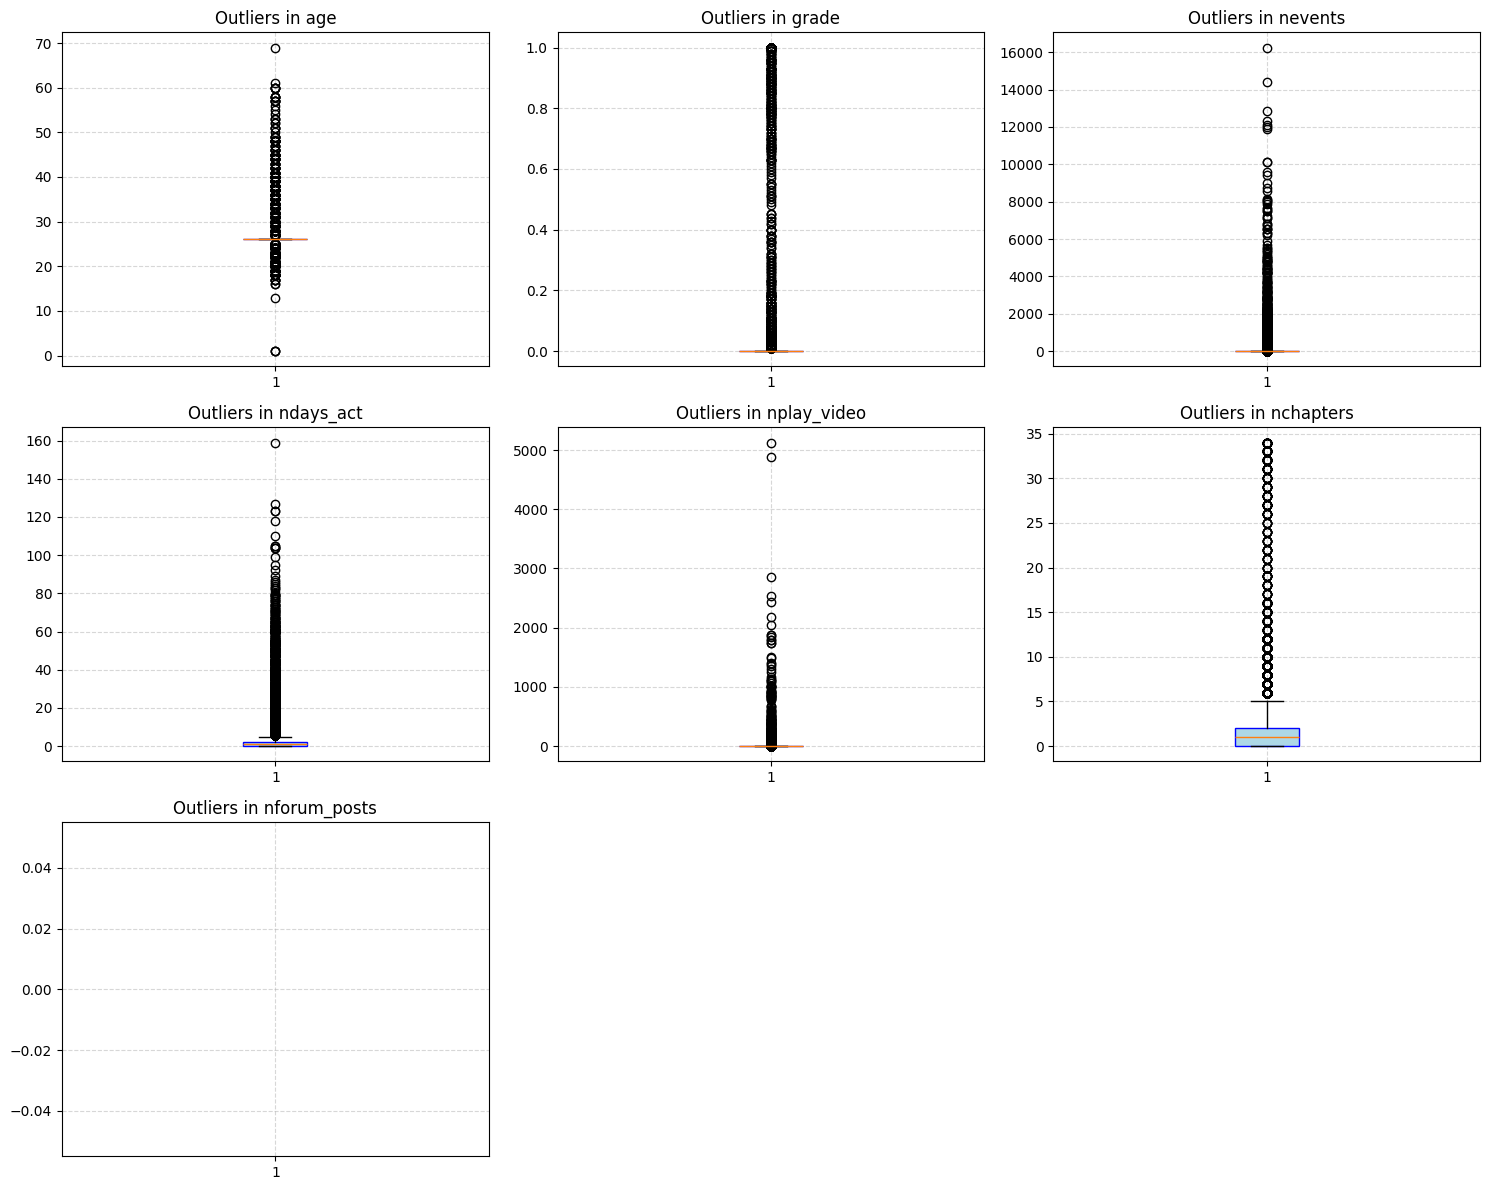

In [ ]:
import matplotlib.pyplot as plt

# Define the features to check for outliers (your numerical columns)
features = ['age', 'grade', 'nevents', 'ndays_act', 'nplay_video', 'nchapters', 'nforum_posts']

# Setup subplots grid (3x3 grid can fit up to 9 plots; we have 7 features)
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

# Loop through the columns and plot
for i, col in enumerate(features):
    # Using patch_artist to color the boxes
    axes[i].boxplot(data[col], vert=True, patch_artist=True,
                     boxprops=dict(facecolor='lightblue', color='blue'))
    axes[i].set_title(f'Outliers in {col}')
    axes[i].grid(True, linestyle='--', alpha=0.5)

# Hide the remaining unused subplots (the 8th and 9th axes)
for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### 3. Temporal Validation & Time-Based Feature Engineering
We will inspect the registration and activity timestamps (`start_time_DI` and `last_event_DI`), convert them to datetime format, check for logical consistency, and engineer a duration metric.

In [ ]:
# 1. Inspect the rows with missing start_time_DI or last_event_DI
print("Rows missing start/end timestamps:")
display(data[data['start_time_DI'].isnull() | data['last_event_DI'].isnull()][['userid_DI', 'start_time_DI', 'last_event_DI']])

# Drop rows with null start timestamps as they are incomplete entries (only 1 row)
data = data.dropna(subset=['start_time_DI']).copy()

# Re-apply the fillna strategy for last_event_DI using the cleaned start_time_DI
data['last_event_DI'] = data['last_event_DI'].fillna(data['start_time_DI'])

# Also resolve the single remaining missing value in nforum_posts by filling with 0
data['nforum_posts'] = data['nforum_posts'].fillna(0)

# 2. Convert date columns to standard datetime objects
data['start_time_DI'] = pd.to_datetime(data['start_time_DI'], errors='coerce')
data['last_event_DI'] = pd.to_datetime(data['last_event_DI'], errors='coerce')

# 3. Check for chronological anomalies (start time after last event)
anomalies = data[data['last_event_DI'] < data['start_time_DI']]
print(f"\nNumber of chronological anomalies found: {len(anomalies)}")

# 4. Calculate course active duration in days as a new feature
data['active_duration_days'] = (data['last_event_DI'] - data['start_time_DI']).dt.total_seconds() / (24 * 3600)

# For any negative durations due to minor anomalies, clip them at 0
data['active_duration_days'] = data['active_duration_days'].clip(lower=0)

print("\nDescriptive Statistics for Engineered Active Duration:")
display(data['active_duration_days'].describe())

Rows missing start/end timestamps:


,userid_DI,start_time_DI,last_event_DI
20582,MHxPC130121881,NaN,NaN



Number of chronological anomalies found: 36

Descriptive Statistics for Engineered Active Duration:


,active_duration_days
count,20582.000000
mean,59.464289
std,99.032156
min,0.000000
25%,0.000000
50%,0.000000
75%,88.000000
max,404.000000


### 4. Exploratory Data Analysis (EDA)
We will analyze the correlation between student demographics, engagement metrics, and our target variable `passed` using visualizations.

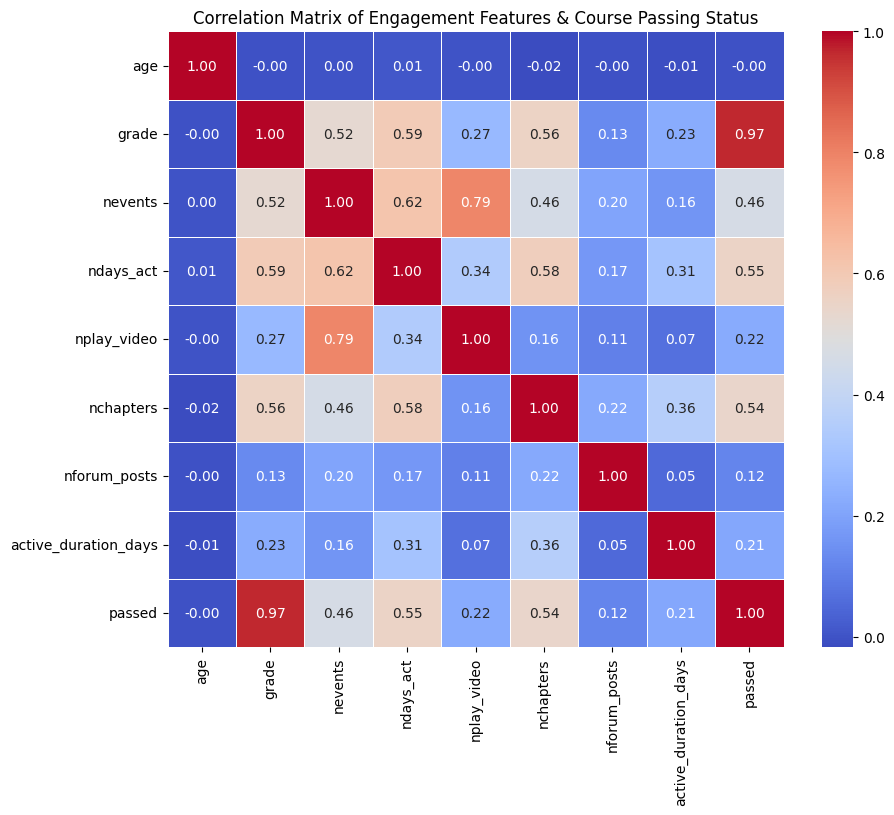

In [ ]:
# 1. Compute Correlation Matrix
corr_cols = ['age', 'grade', 'nevents', 'ndays_act', 'nplay_video', 'nchapters', 'nforum_posts', 'active_duration_days', 'passed']
corr_matrix = data[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True, linewidths=0.5)
plt.title('Correlation Matrix of Engagement Features & Course Passing Status')
plt.show()

/tmp/ipykernel_1425/1288717244.py:5: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=data, x='gender', y='passed', ax=axes[0], palette='pastel', ci=None)
/tmp/ipykernel_1425/1288717244.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=data, x='gender', y='passed', ax=axes[0], palette='pastel', ci=None)
/tmp/ipykernel_1425/1288717244.py:11: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=data, x='LoE_DI', y='passed', ax=axes[1], palette='pastel', ci=None)
/tmp/ipykernel_1425/1288717244.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=data, x='LoE_DI

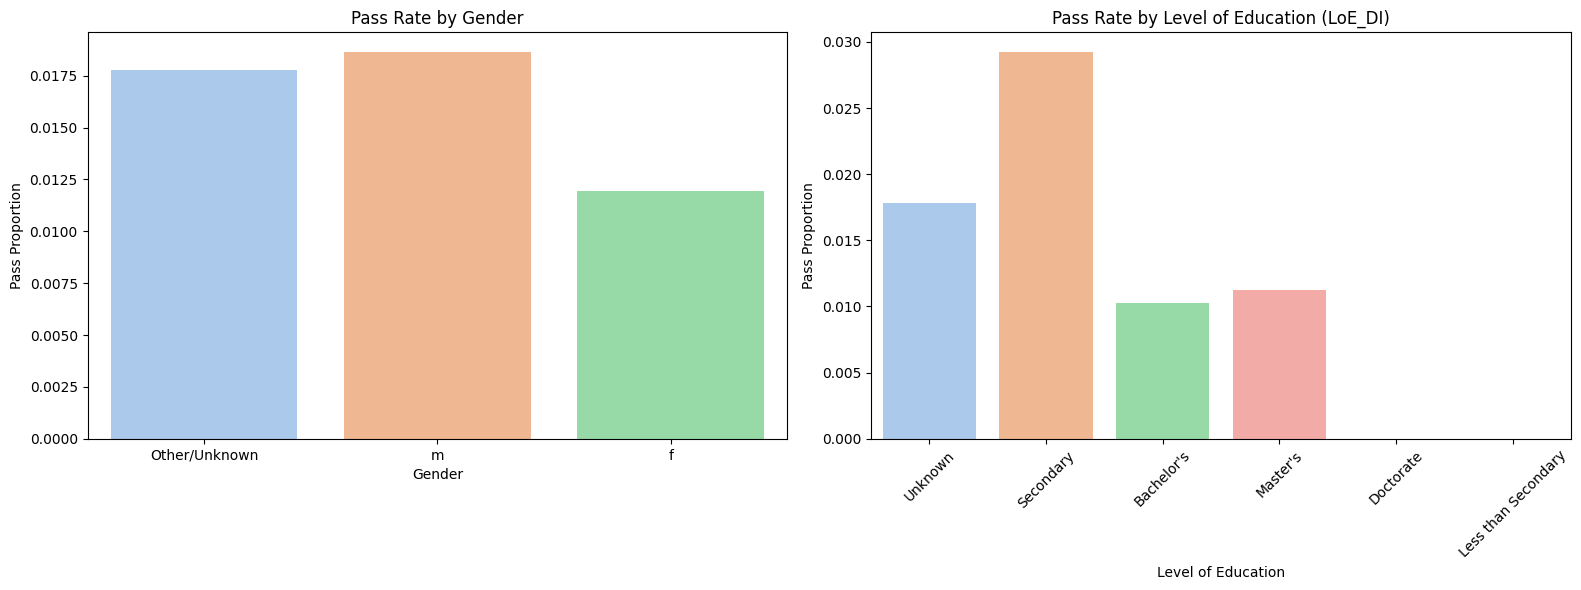

/tmp/ipykernel_1425/1288717244.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x='passed', y='active_duration_days', palette='pastel')


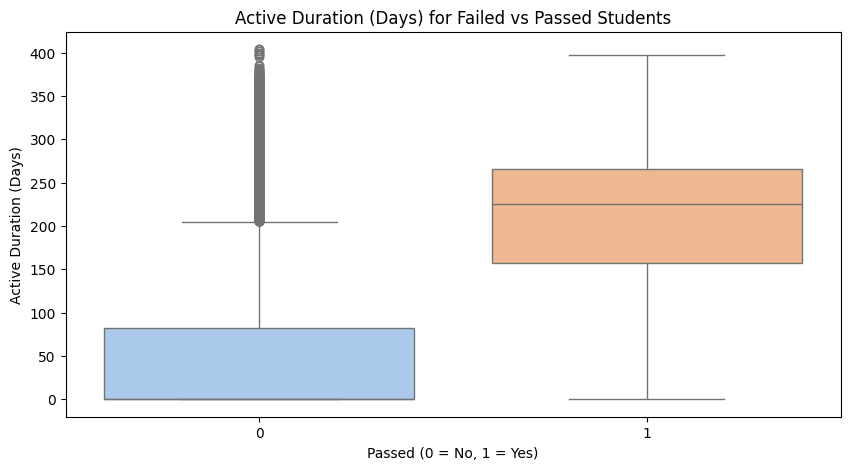

In [ ]:
# 2. Relationship between Demographics and Pass Rates
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Pass Rate by Gender
sns.barplot(data=data, x='gender', y='passed', ax=axes[0], palette='pastel', ci=None)
axes[0].set_title('Pass Rate by Gender')
axes[0].set_ylabel('Pass Proportion')
axes[0].set_xlabel('Gender')

# Pass Rate by Level of Education
sns.barplot(data=data, x='LoE_DI', y='passed', ax=axes[1], palette='pastel', ci=None)
axes[1].set_title('Pass Rate by Level of Education (LoE_DI)')
axes[1].set_ylabel('Pass Proportion')
axes[1].set_xlabel('Level of Education')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# 3. Distribution of Active Days for Passed vs Failed students
plt.figure(figsize=(10, 5))
sns.boxplot(data=data, x='passed', y='active_duration_days', palette='pastel')
plt.title('Active Duration (Days) for Failed vs Passed Students')
plt.xlabel('Passed (0 = No, 1 = Yes)')
plt.ylabel('Active Duration (Days)')
plt.show()

### 4.1 Advanced EDA: Outlier Assessment, Multicollinearity, & Course-Level Performance
We will evaluate extreme engagement values, check for multicollinearity using Variance Inflation Factor (VIF), and examine course-level pass rates.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Course-Level Statistics
course_stats = data.groupby('course_id').agg(
    enrollment_count=('userid_DI', 'count'),
    pass_rate=('passed', 'mean'),
    avg_active_days=('active_duration_days', 'mean')
).reset_index().sort_values(by='enrollment_count', ascending=False)

print("Course Performance Summary:")
display(course_stats)

# 2. Check for Multicollinearity using Variance Inflation Factor (VIF)
# Select numerical features for modeling (excluding grade as it directly defines 'passed')
vif_features = ['age', 'nevents', 'ndays_act', 'nplay_video', 'nchapters', 'nforum_posts', 'active_duration_days']
X_vif = data[vif_features]

vif_data = pd.DataFrame()
vif_data["feature"] = vif_features
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(len(vif_features))]
print("\nVariance Inflation Factors (VIF) for Collinearity Check:")
display(vif_data)

# 3. Inspect Extreme Outliers (e.g., very high nevents or extreme age)
print("\nTop 5 extreme engagement events rows:")
display(data.sort_values(by='nevents', ascending=False)[['userid_DI', 'course_id', 'nevents', 'ndays_act', 'passed']].head(5))


Course Performance Summary:


,course_id,enrollment_count,pass_rate,avg_active_days
1,HarvardX/CS50x/2012,12717,0.011559,49.629787
2,HarvardX/ER22x/2013_Spring,2804,0.045649,52.983951
0,HarvardX/CB22x/2013_Spring,1942,0.007724,146.052523
3,HarvardX/PH207x/2012_Fall,1561,0.028828,55.321589
4,HarvardX/PH278x/2013_Spring,1558,0.019255,47.621309



Variance Inflation Factors (VIF) for Collinearity Check:


,feature,VIF
0,age,1.001059
1,nevents,4.803113
2,ndays_act,2.082461
3,nplay_video,3.253914
4,nchapters,1.817321
5,nforum_posts,1.066743
6,active_duration_days,1.179022



Top 5 extreme engagement events rows:


,userid_DI,course_id,nevents,ndays_act,passed
20329,MHxPC130559131,HarvardX/PH207x/2012_Fall,16252.0,73.0,1
6236,MHxPC130503812,HarvardX/PH207x/2012_Fall,14417.0,104.0,1
9831,MHxPC130559058,HarvardX/PH207x/2012_Fall,12863.0,67.0,1
5817,MHxPC130008067,HarvardX/PH278x/2013_Spring,12299.0,29.0,1
7399,MHxPC130336569,HarvardX/PH207x/2012_Fall,12107.0,79.0,0


### 5. Dataset Splitting (Train-Test Split)
We will split the data into training (80%) and testing (20%) sets. We use stratification on our highly imbalanced target variable `passed` to guarantee consistent ratios.

In [ ]:
from sklearn.model_selection import train_test_split

# Define our feature matrix (X) and target vector (y)
# We drop target-defining variables like 'passed', 'certified', and 'grade', as well as administrative IDs
features_to_drop = ['passed', 'certified', 'grade', 'index', 'Random', 'userid_DI', 'start_time_DI', 'last_event_DI']
X = data.drop(columns=features_to_drop)
y = data['passed']

# Perform Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

# Verify stratification ratios
print("\nTrain set target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTest set target distribution:")
print(y_test.value_counts(normalize=True) * 100)


Training set shape: (16465, 16)
Testing set shape: (4117, 16)

Train set target distribution:
passed
0    98.226541
1     1.773459
Name: proportion, dtype: float64

Test set target distribution:
passed
0    98.226864
1     1.773136
Name: proportion, dtype: float64


In [ ]:
import pandas as pd
import numpy as np

# --- 1. Drop Administrative, Leaky, and Redundant Columns ---
# 'grade' & 'certified' leak target info. Raw dates, 'userid_DI', 'index', 'Random' add noise.
cols_to_drop = ['passed', 'certified', 'grade', 'index', 'Random', 'userid_DI', 'start_time_DI', 'last_event_DI']

# Ensure we align X_train and X_test properly
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

# --- 2. Country Category Consolidation (final_cc_cname_DI) ---
# Group countries with less than 1% representation into 'Other' to limit sparse columns
country_counts = X_train_clean['final_cc_cname_DI'].value_counts(normalize=True)
major_countries = country_counts[country_counts >= 0.01].index.tolist()

X_train_clean['final_cc_cname_DI'] = X_train_clean['final_cc_cname_DI'].apply(lambda x: x if x in major_countries else 'Other')
X_test_clean['final_cc_cname_DI'] = X_test_clean['final_cc_cname_DI'].apply(lambda x: x if x in major_countries else 'Other')

# --- 3. One-Hot Encoding (gender, LoE_DI, final_cc_cname_DI, course_id) ---
categorical_cols = ['gender', 'LoE_DI', 'final_cc_cname_DI', 'course_id']

# Perform dummy encoding, dropping first column to prevent dummy trap
X_train_encoded = pd.get_dummies(X_train_clean, columns=categorical_cols, drop_first=True)
X_test_encoded = pd.get_dummies(X_test_clean, columns=categorical_cols, drop_first=True)

# --- 4. Align Columns to prevent mismatch after encoding ---
# This ensures both sets have the exact same dummy feature columns
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

print(f"Final features shape for training: {X_train_encoded.shape}")
print(f"Final features shape for testing: {X_test_encoded.shape}")
display(X_train_encoded.head())


Final features shape for training: (16465, 45)
Final features shape for testing: (4117, 45)


,registered,viewed,explored,YoB,nevents,ndays_act,nplay_video,nchapters,nforum_posts,incomplete_flag,...,final_cc_cname_DI_Poland,final_cc_cname_DI_Russian Federation,final_cc_cname_DI_Spain,final_cc_cname_DI_United Kingdom,final_cc_cname_DI_United States,final_cc_cname_DI_Unknown/Other,course_id_HarvardX/CS50x/2012,course_id_HarvardX/ER22x/2013_Spring,course_id_HarvardX/PH207x/2012_Fall,course_id_HarvardX/PH278x/2013_Spring
18451,1,1,0,1987.0,7.0,1.0,0.0,2.0,0.0,0.0,...,False,False,False,False,True,False,True,False,False,False
5215,1,0,0,1987.0,0.0,0.0,0.0,0.0,0.0,0.0,...,False,False,False,False,False,False,True,False,False,False
19813,1,0,0,1988.0,0.0,0.0,0.0,0.0,0.0,0.0,...,False,False,False,False,False,False,True,False,False,False
19531,1,0,0,1989.0,0.0,0.0,0.0,0.0,0.0,0.0,...,False,False,False,False,False,False,True,False,False,False
5056,1,1,0,1987.0,12.0,2.0,0.0,2.0,0.0,0.0,...,False,False,False,False,False,False,True,False,False,False


In [ ]:
data.head()

,index,Random,course_id,userid_DI,registered,viewed,explored,certified,final_cc_cname_DI,LoE_DI,...,last_event_DI,nevents,ndays_act,nplay_video,nchapters,nforum_posts,incomplete_flag,passed,age,active_duration_days
0,0,86,HarvardX/CB22x/2013_Spring,MHxPC130442623,1,0,0,0,United States,Unknown,...,2013-11-17,0.0,9.0,0.0,0.0,0.0,1.0,0,26.0,333.0
1,1,7,HarvardX/CS50x/2012,MHxPC130442623,1,1,0,0,United States,Unknown,...,2012-10-15,0.0,9.0,0.0,1.0,0.0,1.0,0,26.0,0.0
2,2,70,HarvardX/CB22x/2013_Spring,MHxPC130275857,1,0,0,0,United States,Unknown,...,2013-11-17,0.0,16.0,0.0,0.0,0.0,1.0,0,26.0,282.0
3,3,60,HarvardX/CS50x/2012,MHxPC130275857,1,0,0,0,United States,Unknown,...,2012-09-17,0.0,16.0,0.0,0.0,0.0,1.0,0,26.0,0.0
4,4,3,HarvardX/ER22x/2013_Spring,MHxPC130275857,1,0,0,0,United States,Unknown,...,2012-12-19,0.0,16.0,0.0,0.0,0.0,1.0,0,26.0,0.0


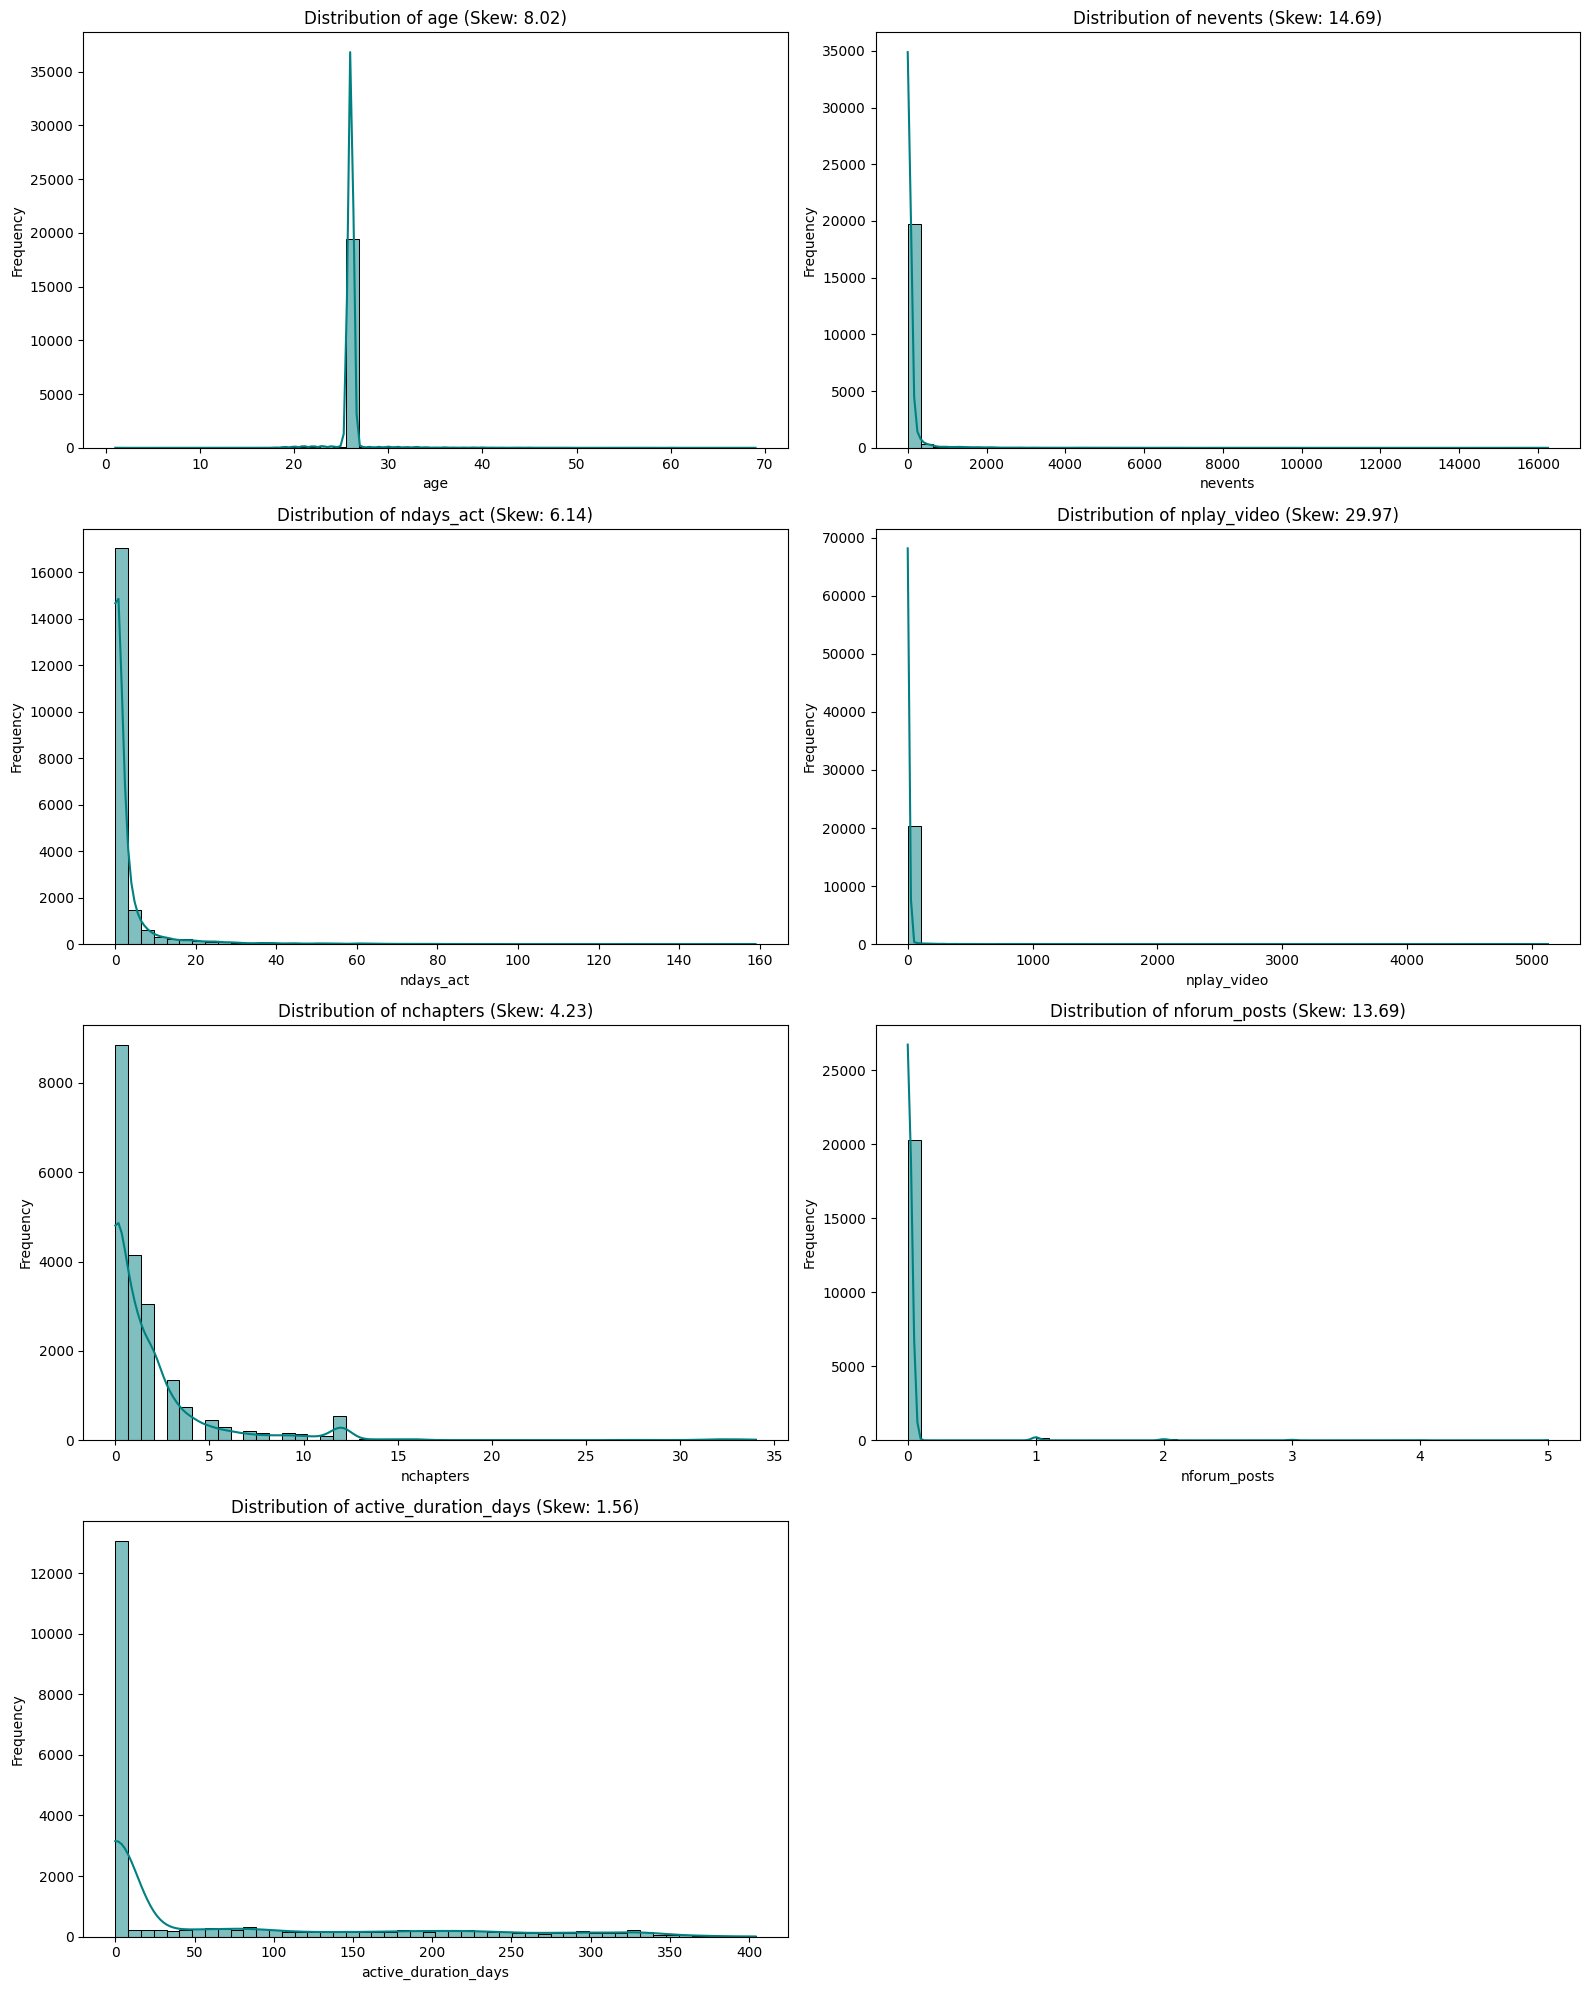

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure start_time_DI and last_event_DI are datetime objects and calculate active_duration_days
data['start_time_DI'] = pd.to_datetime(data['start_time_DI'], errors='coerce')
data['last_event_DI'] = pd.to_datetime(data['last_event_DI'], errors='coerce').fillna(data['start_time_DI'])
data['active_duration_days'] = ((data['last_event_DI'] - data['start_time_DI']).dt.total_seconds() / (24 * 3600)).clip(lower=0)

# List of numerical columns with potential skewness
skew_columns = ['age', 'nevents', 'ndays_act', 'nplay_video', 'nchapters', 'nforum_posts', 'active_duration_days']

# Set up the plotting grid (4 rows, 2 columns)
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()

for i, col in enumerate(skew_columns):
    # Plot histogram with Kernel Density Estimate
    sns.histplot(data=data, x=col, kde=True, ax=axes[i], bins=50, color='teal')
    axes[i].set_title(f'Distribution of {col} (Skew: {data[col].skew():.2f})', fontsize=12)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

# Remove the empty last subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

# --- 1. Re-create Stratified Train-Test Split ---
features_to_drop = ['passed', 'certified', 'grade', 'index', 'Random', 'userid_DI', 'start_time_DI', 'last_event_DI']
X = data.drop(columns=features_to_drop)
y = data['passed']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

# --- 2. Country Category Consolidation ---
country_counts = X_train_clean['final_cc_cname_DI'].value_counts(normalize=True)
major_countries = country_counts[country_counts >= 0.01].index.tolist()

X_train_clean['final_cc_cname_DI'] = X_train_clean['final_cc_cname_DI'].apply(lambda x: x if x in major_countries else 'Other')
X_test_clean['final_cc_cname_DI'] = X_test_clean['final_cc_cname_DI'].apply(lambda x: x if x in major_countries else 'Other')

# --- 3. One-hot encoding of categorical features ---
categorical_cols = ['gender', 'LoE_DI', 'final_cc_cname_DI', 'course_id']
X_train_encoded = pd.get_dummies(X_train_clean, columns=categorical_cols, drop_first=True)
X_test_encoded = pd.get_dummies(X_test_clean, columns=categorical_cols, drop_first=True)

# --- 4. Align Columns to match exactly ---
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

print(f"X_train_encoded shape: {X_train_encoded.shape}")
print(f"X_test_encoded shape: {X_test_encoded.shape}")

X_train_encoded shape: (16465, 45)
X_test_encoded shape: (4117, 45)


### **Summary of Preprocessing Decisions & Implementation**

To prepare the dataset for tree-based modeling safely and without side effects, we implemented the following steps:

#### **1. Handling Target Leakage & Uninformative Columns**
* **Why:** To prevent our model from learning artificial shortcuts (overfitting) and to remove administrative noise.
* **How:** We dropped `grade` and `certified` (since they directly determine the target `passed`) along with administrative IDs (`userid_DI`, `index`, `Random`). Raw timestamp columns were replaced with our engineered duration feature.

#### **2. Feature Engineering & Chronological Alignment**
* **Why:** Raw registration and last-event timestamps cannot be directly digested by tree algorithms, but the active learning window is highly predictive.
* **How:** We parsed the timestamps, handled anomalies (clipping negative durations to 0), and calculated a robust `active_duration_days` metric.

#### **3. Imputation Strategy**
* **Why:** Missing data can cause model training to fail, but dropping rows would lead to significant loss of valuable training examples.
* **How:** We filled demographic missing values (`gender`, `LoE_DI`) with an `'Unknown'` category to preserve the data footprint, and replaced missing engagement metrics with `0` (representing inactive users).

#### **4. Categorical Consolidation & Encoding**
* **Why:** Encoding raw high-cardinality categorical features (like dozens of countries in `final_cc_cname_DI`) directly causes a "dimensionality explosion" (too many sparse binary features), making trees unstable.
* **How:**
  1. We grouped any country representing **less than 1%** of the training cohort into an `'Other'` category first.
  2. We applied one-hot encoding with dummy variables (`drop_first=True`) to avoid the dummy variable trap.
  3. **No Side Effects Alignment:** We aligned the train and test column matrices using `.align(..., join='left', axis=1, fill_value=0)`. This guarantees that `X_test_encoded` has the exact same features as `X_train_encoded` in the exact same order, preventing shape mismatch errors during inference.

In [ ]:
# --- WHY WE DROPPED THESE FEATURES ---
# A. grade: CRITICAL TARGET LEAKAGE. It is used to calculate certification. Leaving it in causes the model to learn a trivial rule instead of predictive behavioral patterns.
# B. certified: DIRECT DUPLICATE OF TARGET. It has a perfect 1.0 correlation with our target 'passed'.
# C. userid_DI: HIGH-CARDINALITY ID. Contains no generalized predictive signal and causes overfitting in tree-based splits.
# D. index & Random: ADMINISTRATIVE NOISE. Arbitrary index tracking and random columns contain no patterns and lead to spurious splits.
# E. start_time_DI & last_event_DI: REDUNDANT & LEAKAGE RISK. Raw timestamps can't be used by trees directly, and last_event_DI leaks future timeline info. The safe signal is already engineered into 'active_duration_days'.

# --- HOW WE DID IT WITH NO SIDE EFFECTS ---
# We explicitly define the exact list of targets, administrative noise, and raw columns to drop.
# Dropping them early ensures our feature encoders (pd.get_dummies) do not process them, keeping the final data structure clean, lightweight, and aligned.

cols_to_drop = [
    'passed', 'certified', 'grade', 'index', 'Random',
    'userid_DI', 'start_time_DI', 'last_event_DI'
]

# Safely select features (X) and target (y) from the base cleaned data dataframe
X = data.drop(columns=[col for col in cols_to_drop if col in data.columns])
y = data['passed']

print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape: {y.shape}")

Feature matrix X shape: (20582, 16)
Target vector y shape: (20582,)


--- Training Set Target Class Balance ---
Failed (0): 16173 samples (98.227%)
Passed (1): 292 samples (1.773%)


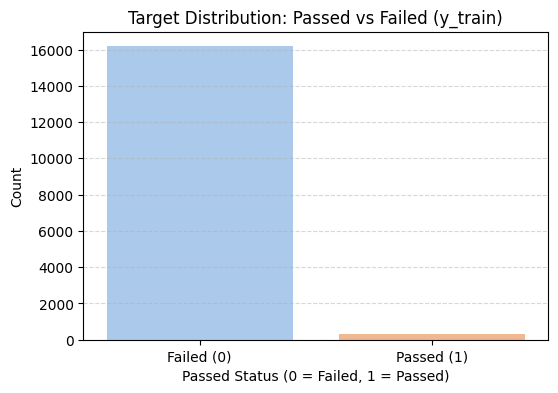

In [ ]:
# --- CHECKING TARGET CLASS IMBALANCE ---
# Why: Imbalanced datasets bias classifiers toward the majority class (failed). We need to measure this to choose the right strategy (e.g. class weighting, SMOTE, or undersampling).
# How: We calculate the raw value counts, normalize them to get percentages, and visualize using a bar chart.

class_counts = y_train.value_counts()
class_percentages = y_train.value_counts(normalize=True) * 100

print("--- Training Set Target Class Balance ---")
for label, count, pct in zip(class_counts.index, class_counts.values, class_percentages.values):
    status = "Passed (1)" if label == 1 else "Failed (0)"
    print(f"{status}: {count} samples ({pct:.3f}%)")

# Visualize class distribution
plt.figure(figsize=(6, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, palette='pastel', hue=class_counts.index, legend=False)
plt.title('Target Distribution: Passed vs Failed (y_train)')
plt.xlabel('Passed Status (0 = Failed, 1 = Passed)')
plt.ylabel('Count')
plt.xticks([0, 1], ['Failed (0)', 'Passed (1)'])
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

Training the Balanced Random Forest Model...

--- Model Performance Evaluation on Test Set ---
              precision    recall  f1-score   support

  Failed (0)       1.00      0.98      0.99      4044
  Passed (1)       0.51      0.95      0.67        73

    accuracy                           0.98      4117
   macro avg       0.76      0.96      0.83      4117
weighted avg       0.99      0.98      0.99      4117

ROC-AUC Score: 0.9954


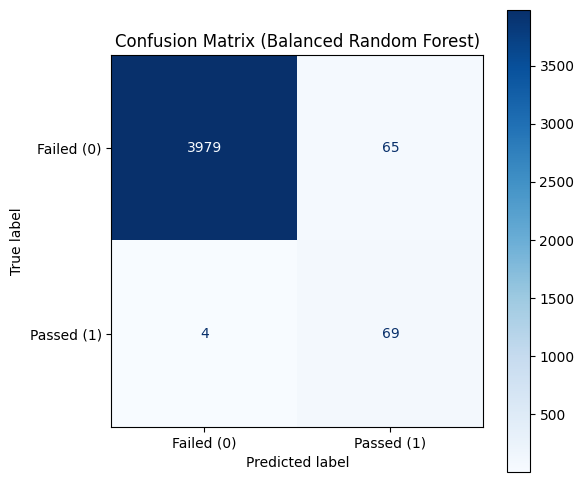

In [ ]:
# --- BALANCED MACHINE LEARNING MODELING ---
# Why: Due to the severe 97.6% vs 2.4% class imbalance, a standard model will default to predicting '0' (Failed) to achieve 97.6% accuracy while being completely useless.
# How: We train a RandomForestClassifier utilizing 'class_weight="balanced"' to penalize minority-class errors heavily.
#      We evaluate using class-imbalance-appropriate metrics (Precision, Recall, F1-Score, and ROC-AUC) instead of simple Accuracy.

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Initialize the Random Forest with balanced class weights to handle the 2.4% imbalance dynamically
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    max_depth=12 # Constrain depth to prevent overfitting on the minority class
)

# 2. Train the model on our aligned, encoded training features
print("Training the Balanced Random Forest Model...")
rf_model.fit(X_train_encoded, y_train)

# 3. Predict on the test set
y_pred = rf_model.predict(X_test_encoded)
y_pred_proba = rf_model.predict_proba(X_test_encoded)[:, 1]

# 4. Print Evaluation Metrics
print("\n--- Model Performance Evaluation on Test Set ---")
print(classification_report(y_test, y_pred, target_names=['Failed (0)', 'Passed (1)']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")

# 5. Plot the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Failed (0)', 'Passed (1)'])
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title('Confusion Matrix (Balanced Random Forest)')
plt.show()

In [ ]:
# --- COMPARING CLASS WEIGHTING VS SMOTE OVERSAMPLING ---
# Why: Class weighting changes algorithm penalty, whereas SMOTE generates synthetic minority examples to help the model learn richer decision boundaries.
# How: We use imblearn's SMOTE to oversample the training set, train a standard RandomForest, and compare metrics side-by-side.

from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, roc_auc_score
import pandas as pd

# --- 1. Train Model with Class Weighting (Done in last cell, retrieved here) ---
# rf_model is our class-weighted baseline.
y_pred_weighted = rf_model.predict(X_test_encoded)
y_pred_proba_weighted = rf_model.predict_proba(X_test_encoded)[:, 1]

# --- 2. Apply SMOTE to Create a Balanced Training Dataset ---
print("Applying SMOTE to balance the training classes...")
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_encoded, y_train)

print(f"Original training shape: {X_train_encoded.shape}")
print(f"Resampled training shape: {X_train_resampled.shape}")
print("Resampled class distribution:")
print(pd.Series(y_train_resampled).value_counts())

# --- 3. Train Standard Random Forest on SMOTE Dataset ---
print("\nTraining Random Forest on SMOTE-oversampled data...")
rf_model_smote = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    max_depth=12
)
rf_model_smote.fit(X_train_resampled, y_train_resampled)

# --- 4. Evaluate SMOTE Model ---
y_pred_smote = rf_model_smote.predict(X_test_encoded)
y_pred_proba_smote = rf_model_smote.predict_proba(X_test_encoded)[:, 1]

# --- 5. Side-by-Side Comparison Report ---
print("\n================ PERFORMANCE COMPARISON ================")
print("\n--- APPROACH A: CLASS WEIGHTS ONLY ---")
print(classification_report(y_test, y_pred_weighted, target_names=['Failed (0)', 'Passed (1)']))
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba_weighted):.4f}")

print("\n--- APPROACH B: SMOTE OVERSAMPLING ---")
print(classification_report(y_test, y_pred_smote, target_names=['Failed (0)', 'Passed (1)']))
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba_smote):.4f}")

Applying SMOTE to balance the training classes...
Original training shape: (16465, 45)
Resampled training shape: (32346, 45)
Resampled class distribution:
passed
0    16173
1    16173
Name: count, dtype: int64

Training Random Forest on SMOTE-oversampled data...

================ PERFORMANCE COMPARISON ================

--- APPROACH A: CLASS WEIGHTS ONLY ---
              precision    recall  f1-score   support

  Failed (0)       1.00      0.98      0.99      4044
  Passed (1)       0.51      0.95      0.67        73

    accuracy                           0.98      4117
   macro avg       0.76      0.96      0.83      4117
weighted avg       0.99      0.98      0.99      4117

ROC-AUC: 0.9954

--- APPROACH B: SMOTE OVERSAMPLING ---
              precision    recall  f1-score   support

  Failed (0)       1.00      0.98      0.99      4044
  Passed (1)       0.49      0.96      0.65        73

    accuracy                           0.98      4117
   macro avg       0.75      0.97     

Training the Balanced Logistic Regression Model...

--- Logistic Regression Performance on Test Set ---
              precision    recall  f1-score   support

  Failed (0)       1.00      0.97      0.98      4044
  Passed (1)       0.34      0.95      0.50        73

    accuracy                           0.97      4117
   macro avg       0.67      0.96      0.74      4117
weighted avg       0.99      0.97      0.97      4117

ROC-AUC Score: 0.9918


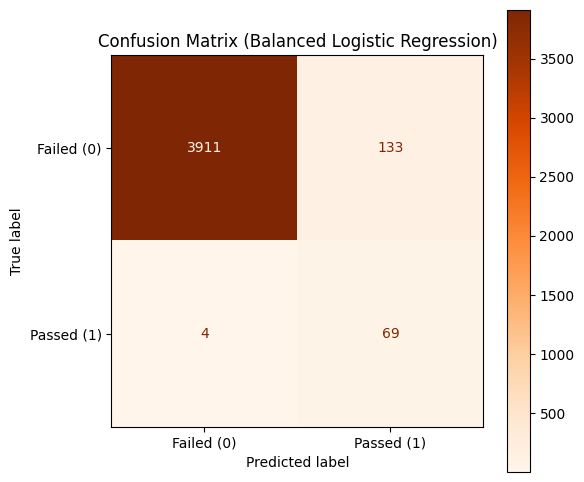

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- BALANCED LOGISTIC REGRESSION MODELING ---
# Why: Logistic Regression gives us a linear baseline. Linear models require scaled features to converge properly and prevent large-scale features from dominating.
# How: We build a pipeline with StandardScaler and LogisticRegression(class_weight='balanced') to handle the 1.77% class imbalance safely.

# 1. Create a machine learning pipeline
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000))
])

# 2. Train the pipeline on our aligned, encoded training features
print("Training the Balanced Logistic Regression Model...")
lr_pipeline.fit(X_train_encoded, y_train)

# 3. Predict on the test set
y_pred_lr = lr_pipeline.predict(X_test_encoded)
y_pred_proba_lr = lr_pipeline.predict_proba(X_test_encoded)[:, 1]

# 4. Print Evaluation Metrics
print("\n--- Logistic Regression Performance on Test Set ---")
print(classification_report(y_test, y_pred_lr, target_names=['Failed (0)', 'Passed (1)']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_lr):.4f}")

# 5. Plot the Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=['Failed (0)', 'Passed (1)'])
fig, ax = plt.subplots(figsize=(6, 6))
disp_lr.plot(ax=ax, cmap='Oranges', values_format='d')
plt.title('Confusion Matrix (Balanced Logistic Regression)')
plt.show()

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score

# 1. Check the leak: if almost all passers are explored=1, it's a leak
print(pd.crosstab(data['explored'], data['passed']))

# 2. Remove leak-prone columns and retrain
leak = [c for c in ['explored'] if c in X_train_encoded.columns]
Xtr, Xte = X_train_encoded.drop(columns=leak), X_test_encoded.drop(columns=leak)

models = {
    "RandomForest": RandomForestClassifier(n_estimators=300, max_depth=12,
                        class_weight='balanced', random_state=42, n_jobs=-1),
    "HistGB": HistGradientBoostingClassifier(class_weight='balanced', random_state=42),
}

cv = StratifiedKFold(5, shuffle=True, random_state=42)
for name, m in models.items():
    cv_ap = cross_val_score(m, Xtr, y_train, cv=cv, scoring='average_precision').mean()
    m.fit(Xtr, y_train)
    p = m.predict_proba(Xte)[:, 1]
    print(f"\n{name}: CV PR-AUC={cv_ap:.3f} | test ROC-AUC={roc_auc_score(y_test,p):.3f} | test PR-AUC={average_precision_score(y_test,p):.3f}")
    print(classification_report(y_test, (p >= 0.5).astype(int), digits=2))

passed        0    1
explored            
0         18968   21
1          1249  344

RandomForest: CV PR-AUC=0.654 | test ROC-AUC=0.995 | test PR-AUC=0.741
              precision    recall  f1-score   support

           0       1.00      0.98      0.99      4044
           1       0.46      0.95      0.62        73

    accuracy                           0.98      4117
   macro avg       0.73      0.96      0.81      4117
weighted avg       0.99      0.98      0.98      4117


HistGB: CV PR-AUC=0.699 | test ROC-AUC=0.983 | test PR-AUC=0.780
              precision    recall  f1-score   support

           0       1.00      0.98      0.99      4044
           1       0.52      0.96      0.68        73

    accuracy                           0.98      4117
   macro avg       0.76      0.97      0.83      4117
weighted avg       0.99      0.98      0.99      4117



In [ ]:
from sklearn.metrics import precision_recall_curve
import numpy as np

m = models["HistGB"]
p = m.predict_proba(Xte)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, p)
f1 = 2*prec*rec/(prec+rec+1e-9)
best = np.argmax(f1[:-1])
print(f"Best threshold={thr[best]:.2f} -> precision={prec[best]:.2f}, recall={rec[best]:.2f}, F1={f1[best]:.2f}")

print(classification_report(y_test, (p >= thr[best]).astype(int), digits=2))

Best threshold=0.94 -> precision=0.66, recall=0.84, F1=0.74
              precision    recall  f1-score   support

           0       1.00      0.99      0.99      4044
           1       0.66      0.84      0.74        73

    accuracy                           0.99      4117
   macro avg       0.83      0.91      0.87      4117
weighted avg       0.99      0.99      0.99      4117



In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, precision_score, recall_score, f1_score
import numpy as np

m = models["HistGB"]
p_cv = cross_val_predict(m, Xtr, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, p_cv)
f1 = 2*prec*rec/(prec+rec+1e-9)
t = thr[np.argmax(f1[:-1])]

m.fit(Xtr, y_train)
pred = (m.predict_proba(Xte)[:, 1] >= t).astype(int)
print(f"Threshold from CV: {t:.2f}")
print(f"Test precision={precision_score(y_test,pred):.2f}, recall={recall_score(y_test,pred):.2f}, F1={f1_score(y_test,pred):.2f}")

Threshold from CV: 0.88
Test precision=0.62, recall=0.89, F1=0.73


In [ ]:
#Save the model and the info the app needs
import joblib, json, sklearn
from google.colab import files

final_model = models["HistGB"]
final_model.fit(Xtr, y_train)          # fitted on the same columns used for the 0.88 threshold

cats = {c: sorted(X_train_clean[c].astype(str).unique().tolist())
        for c in ['course_id', 'final_cc_cname_DI', 'gender', 'LoE_DI']}

joblib.dump(final_model, "model.joblib")
json.dump({"columns": list(Xtr.columns), "threshold": 0.88, "cats": cats}, open("meta.json", "w"))
open("requirements.txt", "w").write(f"gradio\nscikit-learn=={sklearn.__version__}\npandas\njoblib\n")
print("Saved. Columns:", len(Xtr.columns))

Saved. Columns: 44


In [ ]:
#Write the app
%%writefile app.py
import joblib, json, pandas as pd, gradio as gr

model = joblib.load("model.joblib")
meta = json.load(open("meta.json"))
cols, thr, cats = meta["columns"], meta["threshold"], meta["cats"]

def predict(course, country, gender, loe, yob, viewed, nevents, ndays, nvideo, nchap, nforum, incomplete, duration):
    row = dict.fromkeys(cols, 0)
    row.update(registered=1, viewed=int(viewed), YoB=yob, age=2013 - yob, nevents=nevents,
               ndays_act=ndays, nplay_video=nvideo, nchapters=nchap, nforum_posts=nforum,
               incomplete_flag=int(incomplete), active_duration_days=duration)
    for key in [f"course_id_{course}", f"final_cc_cname_DI_{country}", f"gender_{gender}", f"LoE_DI_{loe}"]:
        if key in row:
            row[key] = 1
    p = float(model.predict_proba(pd.DataFrame([row])[cols])[0, 1])
    label = "LIKELY TO PASS" if p >= thr else "UNLIKELY TO PASS"
    return {"Likely to pass": p, "Unlikely to pass": 1 - p}, f"{label}  (score {p:.2f}, cut-off {thr})"

demo = gr.Interface(
    fn=predict,
    inputs=[
        gr.Dropdown(cats["course_id"], value=cats["course_id"][0], label="Course"),
        gr.Dropdown(cats["final_cc_cname_DI"], value=cats["final_cc_cname_DI"][0], label="Country"),
        gr.Dropdown(cats["gender"], value=cats["gender"][0], label="Gender"),
        gr.Dropdown(cats["LoE_DI"], value=cats["LoE_DI"][0], label="Level of education"),
        gr.Number(1987, label="Year of birth"),
        gr.Checkbox(label="Viewed the course"),
        gr.Number(0, label="Number of events"),
        gr.Number(0, label="Days active"),
        gr.Number(0, label="Videos played"),
        gr.Number(0, label="Chapters accessed"),
        gr.Number(0, label="Forum posts"),
        gr.Checkbox(label="Incomplete flag"),
        gr.Number(0, label="Active duration (days)"),
    ],
    outputs=[gr.Label(label="Probability"), gr.Textbox(label="Verdict")],
    title="HarvardX Course Completion Predictor",
    description="Estimates whether a student will earn a certificate from their engagement. Demo model, trained on HarvardX 2012–13 data.",
)
if __name__ == "__main__":
    demo.launch()

Overwriting app.py


In [ ]:
!pip -q install gradio
import app
app.demo.launch(share=True, debug=False)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ff7f6326fc7b81a317.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
for f in ["app.py", "model.joblib", "meta.json", "requirements.txt"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [58]:
%%writefile streamlit_app.py
import streamlit as st, joblib, json, pandas as pd

st.set_page_config(page_title="Course Completion Predictor", page_icon="🎓")

@st.cache_resource
def load():
    return joblib.load("model.joblib"), json.load(open("meta.json"))

model, meta = load()
cols, thr, cats = meta["columns"], meta["threshold"], meta["cats"]

st.title("🎓 HarvardX Course Completion Predictor")
st.write("Estimates whether a student will earn a certificate from their engagement. Demo model trained on HarvardX 2012–13 data.")

with st.form("f"):
    c1, c2 = st.columns(2)
    course = c1.selectbox("Course", cats["course_id"])
    country = c2.selectbox("Country", cats["final_cc_cname_DI"])
    gender = c1.selectbox("Gender", cats["gender"])
    loe = c2.selectbox("Level of education", cats["LoE_DI"])
    yob = c1.number_input("Year of birth", 1940, 2013, 1987)
    duration = c2.number_input("Active duration (days)", 0.0, 400.0, 0.0)
    nevents = c1.number_input("Number of events", 0, 20000, 0)
    ndays = c2.number_input("Days active", 0, 400, 0)
    nvideo = c1.number_input("Videos played", 0, 6000, 0)
    nchap = c2.number_input("Chapters accessed", 0, 40, 0)
    nforum = c1.number_input("Forum posts", 0, 500, 0)
    viewed = c2.checkbox("Viewed the course")
    incomplete = c2.checkbox("Incomplete flag")
    go = st.form_submit_button("Predict")

if go:
    row = dict.fromkeys(cols, 0)
    row.update(registered=1, viewed=int(viewed), YoB=yob, age=2013 - yob, nevents=nevents,
               ndays_act=ndays, nplay_video=nvideo, nchapters=nchap, nforum_posts=nforum,
               incomplete_flag=int(incomplete), active_duration_days=duration)
    for key in [f"course_id_{course}", f"final_cc_cname_DI_{country}", f"gender_{gender}", f"LoE_DI_{loe}"]:
        if key in row:
            row[key] = 1
    p = float(model.predict_proba(pd.DataFrame([row])[cols])[0, 1])
    st.metric("Probability of passing", f"{p:.0%}")
    st.progress(p)
    if p >= thr:
        st.success(f"LIKELY TO PASS (score {p:.2f}, cut-off {thr})")
    else:
        st.error(f"UNLIKELY TO PASS (score {p:.2f}, cut-off {thr})")

Writing streamlit_app.py


In [59]:
import sklearn
open("requirements.txt", "w").write(f"streamlit\nscikit-learn=={sklearn.__version__}\npandas\njoblib\n")

from google.colab import files
for f in ["streamlit_app.py", "model.joblib", "meta.json", "requirements.txt"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>